# NN_L2_gd_paths

**Gradient descent and momentum on the real mean-squared-error surface of a one-variable regression of California house values on median income: raw (ill-conditioned) against standardised income.**

Neural Networks and Deep Learning (NN), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L2/NN_L2_gd_paths/NN_L2_gd_paths.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 2 of *Neural Networks and Deep Learning*: the chart `gd_paths` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

condition number, raw income = 104.3   [surface.cond_raw]
MSE after 60 GD steps, raw = 1.4864   [surface.mse_gd_raw_60]
MSE after 60 momentum steps, raw = 0.7037   [surface.mse_mom_raw_60]
MSE after 60 GD steps, standardised = 0.7011   [surface.mse_gd_std_60]


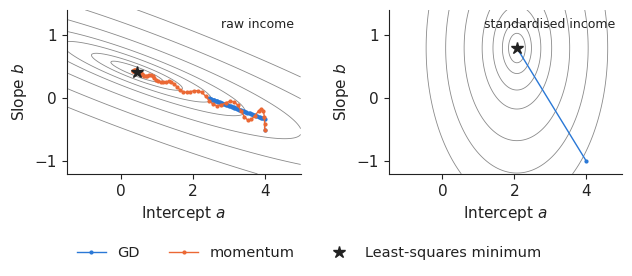

In [3]:
ca = pd.read_csv(DATA + 'california_housing.csv'); x = ca['MedInc'].values.astype(float); y = ca['MedHouseVal_100k_usd'].values.astype(float)
def setup(xf):
    X = np.c_[np.ones_like(xf), xf]; return X, 2 * X.T @ X / len(xf), np.linalg.lstsq(X, y, rcond=None)[0]
def gd(X, w0, lr, steps, beta=0.0):
    w, v, p = np.array(w0, float), np.zeros(2), [np.array(w0, float)]
    for _ in range(steps):
        v = beta * v + 2 * X.T @ (X @ w - y) / len(y); w = w - lr * v; p.append(w.copy())
    return np.array(p)
Xr, Hr, wr = setup(x); Xs, Hs, ws = setup((x - x.mean()) / x.std())
er, es = np.linalg.eigvalsh(Hr), np.linalg.eigvalsh(Hs)
pg = gd(Xr, [4.0, -0.5], 1 / er.max(), 60); pm = gd(Xr, [4.0, -0.5], 0.5 / er.max(), 60, 0.9); ps = gd(Xs, [4.0, -1.0], 1 / es.max(), 60)
mse = lambda X, w: float(np.mean((X @ w - y) ** 2))
show('surface.cond_raw', 'condition number, raw income', round(float(er.max() / er.min()), 1))
show('surface.mse_gd_raw_60', 'MSE after 60 GD steps, raw', round(mse(Xr, pg[-1]), 4))
show('surface.mse_mom_raw_60', 'MSE after 60 momentum steps, raw', round(mse(Xr, pm[-1]), 4))
show('surface.mse_gd_std_60', 'MSE after 60 GD steps, standardised', round(mse(Xs, ps[-1]), 4))
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.8))
for ax, (X, w_, paths, lab) in zip(axs, ((Xr, wr, [(pg, PAL['data'], 'GD'), (pm, PAL['model'], 'momentum')], 'raw income'),
                                         (Xs, ws, [(ps, PAL['data'], 'GD')], 'standardised income'))):
    A, Bm = np.meshgrid(np.linspace(min(w_[0], -0.5) - 1, 5, 160), np.linspace(-1.2, 1.4, 160))
    L = (np.mean(y ** 2) - 2 * (A * np.mean(X[:, 0] * y) + Bm * np.mean(X[:, 1] * y)) + A ** 2 * np.mean(X[:, 0] ** 2)
         + 2 * A * Bm * np.mean(X[:, 0] * X[:, 1]) + Bm ** 2 * np.mean(X[:, 1] ** 2))
    ax.contour(A, Bm, L, levels=np.quantile(L, [0.01, 0.03, 0.08, 0.15, 0.3, 0.5, 0.7]), colors=['#8a8a8a'], linewidths=0.6)
    for p, c, l in paths:
        ax.plot(p[:, 0], p[:, 1], 'o-', ms=2, lw=1, color=c, label=l)
    ax.plot(*w_, '*', color='#222222', ms=9, label='Least-squares minimum')
    ax.set_xlabel('Intercept $a$'); ax.set_ylabel('Slope $b$'); ax.text(0.97, 0.95, lab, transform=ax.transAxes, ha='right', va='top', fontsize=9)
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('gd_paths.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()